# **Módulo de Inteligencia Artificial**
## *1. Definición del Problema Empresarial*
El centro dental pierde ingresos y los pacientes no logran sus resultados clínicos debido al abandono de los tratamientos largos. Este modelo busca predecir qué pacientes tienen mayor probabilidad de abandonar, permitiendo al área de Atención al Paciente priorizar sus campañas de fidelización basándose en el nivel de riesgo.


### Importación de librerías y conexión a Base Dimensional

In [1]:
import pyodbc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

SERVER = r'localhost\SQLEXPRESS'
DM_DB = 'DentalCenterDB'
driver = [d for d in pyodbc.drivers() if 'SQL Server' in d][-1]
conn_str = f'DRIVER={{{driver}}};SERVER={SERVER};DATABASE={DM_DB};Trusted_Connection=yes;TrustServerCertificate=yes;'
conn = pyodbc.connect(conn_str)
print("Conectado al DataMart exitosamente.")

Conectado al DataMart exitosamente.


## *2. Descripción y Selección de Datos (EDA)*
Se extrae todos los datos consolidados desde el esquema dimensional `Fact_Atenciones` cruzado con `Dim_Paciente` y `Dim_Tratamiento`. Se realizará un Análisis Exploratorio de Datos (EDA) para identificar las variables con mayor poder predictivo sobre la variable objetivo `Target_Abandono`.

In [5]:
query = """
SELECT * FROM DW.vw_Dataset_ML
"""
df = pd.read_sql(query, conn)
display(df.head())

C:\Users\fabri\AppData\Local\Temp\ipykernel_20384\621242899.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,SK_Paciente,Edad,Genero,Barrio,Total_Citas,Total_Ausencias,Prom_Tiempo_Espera,Total_Pagado,Costo_Tratamiento,Target_Abandono
0,1,13,M,PARQUE MOSCOSO,1,1,3602,45.0,45.0,1
1,2,16,M,SANTO ANT├öNIO,1,0,-582,45.0,45.0,0
2,3,23,F,INHANGUET├ü,2,0,28170,90.0,45.0,0
3,4,28,F,JARDIM DA PENHA,2,0,18598,90.0,45.0,0
4,5,32,M,ITARAR├ë,1,0,22464,45.0,45.0,0


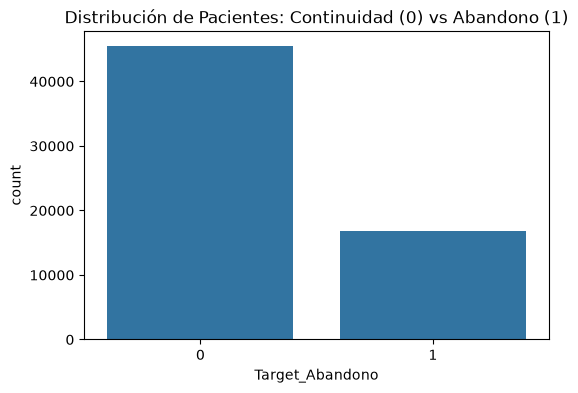

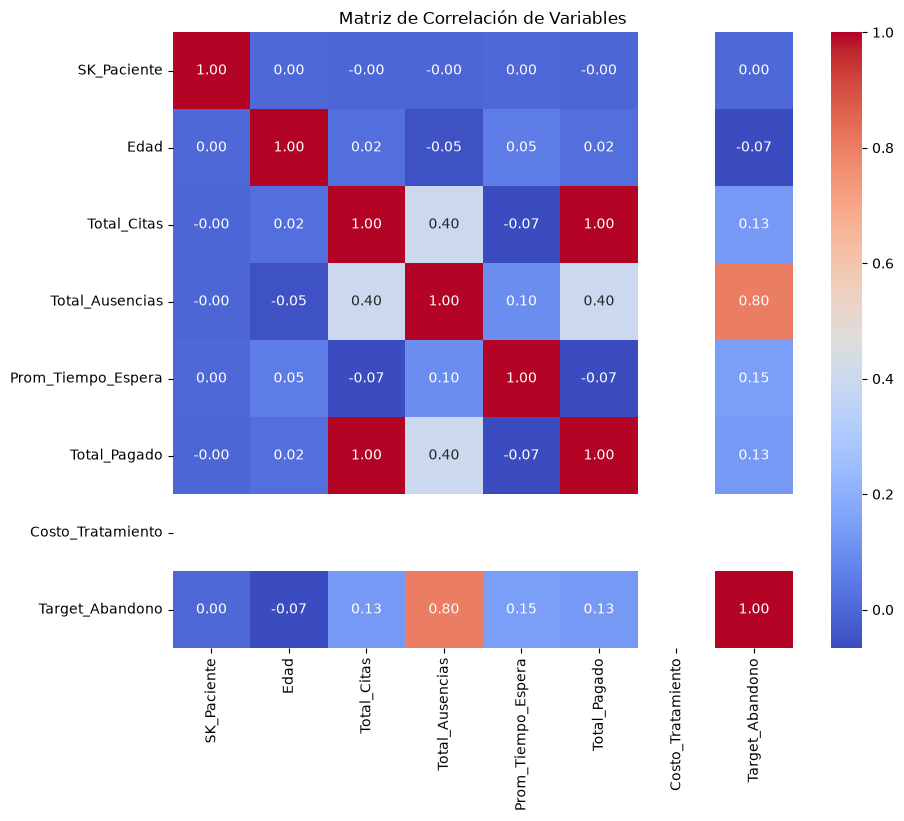

In [4]:
# Visualización del desbalance de clases
plt.figure(figsize=(6,4))
sns.countplot(x='Target_Abandono', data=df)
plt.title('Distribución de Pacientes: Continuidad (0) vs Abandono (1)')
plt.show()

# Matriz de Correlación para selección de variables numéricas
plt.figure(figsize=(10,8))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación de Variables')
plt.show()
# display(df)

## *3. Variables, Limpieza y División de Datos*
> **Análisis pendiente:** (Aquí redactarás por qué seleccionaste ciertas variables tras ver la matriz de correlación de los datos reales).

Para el entrenamiento, utilizaremos el 80% de los datos y reservaremos el 20% para la validación, estratificando por la variable objetivo para mantener la proporción de abandonos.

In [12]:
# Selección final fundamentada en el EDA
X = df[['Edad', 'Total_Citas', 'Total_Ausencias', 'Prom_Tiempo_Espera', 'Total_Pagado', 'Costo_Tratamiento']]
y = df['Target_Abandono']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Set de entrenamiento: {X_train.shape[0]} pacientes.")
print(f"Set de prueba: {X_test.shape[0]} pacientes.")

Set de entrenamiento: 49834 pacientes.
Set de prueba: 12459 pacientes.


## *4. Selección, Entrenamiento y Evaluación*
Se evaluarán dos modelos supervisados de clasificación:
1. **Regresión Logística:** Como modelo base interpretable.
2. **Random Forest:** Conjunto de árboles de decisión que maneja mejor las relaciones no lineales.

La métrica principal a optimizar será el **Recall**, ya que el costo de negocio de perder un paciente (Falso Negativo) es mayor que el de hacer una llamada de fidelización innecesaria (Falso Positivo).

--- Regresión Logística ---
Accuracy: 0.9991 | Recall: 1.0000 | F1: 0.9984

--- Random Forest ---
Accuracy: 0.9999 | Recall: 1.0000 | F1: 0.9999


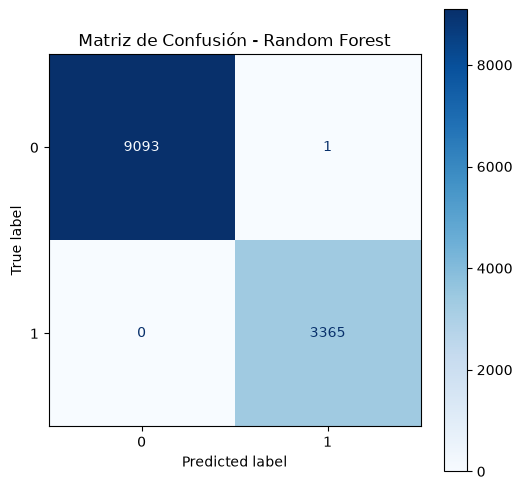

In [14]:
# Entrenamiento
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# Comparación de métricas
print("--- Regresión Logística ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f} | Recall: {recall_score(y_test, y_pred_lr):.4f} | F1: {f1_score(y_test, y_pred_lr):.4f}")

print("\n--- Random Forest ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f} | Recall: {recall_score(y_test, y_pred_rf):.4f} | F1: {f1_score(y_test, y_pred_rf):.4f}")

# Matriz de Confusión del modelo ganador (Random Forest)
fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, cmap='Blues', ax=ax)
plt.title('Matriz de Confusión - Random Forest')
plt.show()

## *5. Integración de Resultados y Toma de Decisiones*
Basado en las métricas de evaluación, se selecciona el modelo Random Forest. Sus predicciones probabilísticas se categorizan en tres niveles de riesgo (Alto, Medio, Bajo). Estos resultados se inyectan de vuelta al DataMart en SQL Server para alimentar el simulador What-If en Power BI, cerrando el ciclo analítico.

In [16]:
# Generación de predicciones finales
probabilidades = rf_model.predict_proba(X)[:, 1]
df['Probabilidad_Abandono'] = probabilidades
df['Prediccion_Binary'] = (probabilidades >= 0.5).astype(int)

def asignar_riesgo(prob):
    if prob >= 0.65: return 'Riesgo Alto'
    elif prob >= 0.35: return 'Riesgo Medio'
    else: return 'Riesgo Bajo'

df['Nivel_Riesgo'] = df['Probabilidad_Abandono'].apply(asignar_riesgo)

# Exportación a SQL Server
cursor = conn.cursor()
cursor.execute("DELETE FROM Resultados_Prediccion_IA;")

for _, row in df.iterrows():
    cursor.execute("""
        INSERT INTO Resultados_Prediccion_IA 
        (SK_Paciente, Probabilidad_Abandono, Nivel_Riesgo, Prediccion_Binary)
        VALUES (?, ?, ?, ?)""",
        (int(row['SK_Paciente']),float(row['Probabilidad_Abandono']), row['Nivel_Riesgo'], int(row['Prediccion_Binary'])))

conn.commit()
cursor.close()
conn.close()
print("¡Integración exitosa! Scores exportados a la tabla Resultados_Prediccion_IA para Power BI.")

¡Integración exitosa! Scores exportados a la tabla Resultados_Prediccion_IA para Power BI.
